# 04 · Interfaz web con Gradio y asistente conversacional

**Proyecto:** Emotion Detection Assistant · **Autor:** Edwar Trujillo · **Materia:** Inteligencia Artificial (Ingeniería de Sistemas, FUP)

**Objetivo (Fases 4 y 5):** llevar el sistema de la Fase 3 (Haar Cascade + CNN con TTA + suavizado + historial) a una **aplicación web local** que muestre:
1. El **video de la webcam en vivo** con el rostro detectado.
2. La **emoción actual** con su **confianza**.
3. El **panel de probabilidades** de las 7 emociones.
4. La **gráfica del historial** de emociones.
5. Un **asistente conversacional** (Google Gemini) al que se le puede preguntar cómo se ve o cómo se ha sentido la persona según el historial *(Fase 5)*.

**Estructura del notebook**
- **Parte 1:** importar el código de las fases anteriores desde el módulo `src/` y verificarlo.
- **Parte 2:** cómo funciona Gradio, las funciones que procesan cada cuadro y el asistente (2.6-2.7).
- **Parte 3:** construir y lanzar la interfaz.
- **Parte 4:** resultados de la sesión (rendimiento, historial y asistente) y evidencias para el reporte.

> **Privacidad:** el video lo captura el navegador y lo envía solo a tu propio PC (`127.0.0.1`). Ningún cuadro se guarda en disco ni en este notebook: el cuadro anotado viaja al navegador codificado en memoria. Solo se guardan **etiquetas y números** (historial y métricas). Al asistente (Gemini, en internet) **solo se le envían etiquetas y porcentajes**, nunca imágenes.
>
> **Requisito de la Fase 5:** archivo `.env` en la raíz del proyecto con `GEMINI_API_KEY`, `GEMINI_MODEL` y `GEMINI_FALLBACK_MODEL` (ver `.env.example`). Sin él, la interfaz funciona igual pero el chat muestra un aviso.

## Parte 1 · El código de las fases anteriores como módulo

En la Fase 3 las funciones vivían dentro del notebook `03`. Para usarlas aquí sin copiarlas y pegarlas, se movieron a **módulos de Python** (archivos `.py`) en la carpeta `src/`:

| Archivo | Qué contiene |
|---|---|
| `src/__init__.py` | Marca la carpeta `src` como **paquete** de Python (permite escribir `from src.… import …`). |
| `src/emotion_detection.py` | Clase `EmotionDetector` (carga el modelo y el Haar Cascade; `detect_faces`, `extract_face`, `predict` con `tf.function` + TTA, `analyze_frame`), `draw_results`, etiquetas y colores. |
| `src/emotion_tracking.py` | `EmotionSmoother` (media móvil, N = 10), `EmotionHistory` (1 muestra/s, `summary()`) y `count_label_changes`. |
| `src/assistant.py` *(Fase 5)* | `GeminiAssistant` (llamada a Gemini con modelo de respaldo), `build_emotion_context` (convierte el historial en texto con etiquetas y %), `validate_message`. Se explica en la Parte 2.6. |

**¿Por qué un módulo?**
- **Una sola fuente de verdad (principio DRY, *Don't Repeat Yourself*):** si se corrige algo, se corrige en un lugar y lo usan todos los notebooks.
- **Clase en lugar de funciones sueltas:** `EmotionDetector` carga el modelo **una vez** en su `__init__` y lo guarda como atributo (`self.model`). Así no dependemos de variables globales del notebook.
- **Cambio respecto a la Fase 3:** `analyze_frame()` recibe `color_order` (`"BGR"` u `"RGB"`), porque Gradio entrega los cuadros en **RGB** y OpenCV en **BGR** (se explica en la celda de verificación). `EmotionHistory` recibe la lista de clases al crearse.

**`sys.path`:** es la lista de carpetas donde Python busca los módulos al hacer `import`. Jupyter arranca en `notebooks/`, así que agregamos la **raíz del proyecto** para que encuentre `src/`.

> Si modificas un `.py` de `src/`, haz **Kernel → Restart Kernel** y vuelve a ejecutar: Python importa cada módulo una sola vez por sesión.

In [16]:
# Muestra las gráficas de Matplotlib dentro del notebook
%matplotlib inline

# --- Configuración ANTES de importar las librerías ---
import os
os.environ["GRADIO_ANALYTICS_ENABLED"] = "False"   # Gradio no envía estadísticas de uso a internet
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"           # oculta los mensajes informativos de TensorFlow

# --- Librerías ---
import sys
import json
import time
import base64              # convertir el cuadro JPEG a texto para mostrarlo en el navegador
import threading           # candado (Lock) para que dos eventos no modifiquen la sesión a la vez
from collections import deque
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.figure import Figure   # figuras sin pyplot: seguras para usar desde Gradio (hilos)
from IPython.display import HTML, display
import tensorflow as tf
import keras
import gradio as gr

# --- Rutas: el notebook vive en notebooks/, la raíz del proyecto es la carpeta padre ---
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
MODELS_DIR = PROJECT_ROOT / "models"
METRICS_DIR = PROJECT_ROOT / "reports" / "metrics"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))           # para que Python encuentre la carpeta src/

# --- Código de la Fase 3, ahora importado desde src/ ---
from src.emotion_detection import EmotionDetector, draw_results, EMOTION_LABELS_ES, hex_color, FACE_SIZE
from src.emotion_tracking import EmotionSmoother, EmotionHistory, count_label_changes, SMOOTHING_WINDOW
# --- Fase 5: asistente conversacional con Gemini ---
from src.assistant import (GeminiAssistant, build_emotion_context, validate_message, message_text,
                           MAX_MESSAGE_CHARS, SYSTEM_INSTRUCTION)

from importlib.metadata import version
print(f"TensorFlow: {tf.__version__} | Keras: {keras.__version__} | OpenCV: {cv2.__version__} | Gradio: {gr.__version__} "
      f"| google-genai: {version('google-genai')}")
print("Raíz del proyecto:", PROJECT_ROOT)

TensorFlow: 2.21.0 | Keras: 3.15.1 | OpenCV: 4.14.0 | Gradio: 6.32.0 | google-genai: 3.6.1
Raíz del proyecto: C:\Users\Personal\Projects\emotion-detection-assistant


In [17]:
# --- Crear el detector: carga el modelo, el Haar Cascade y compila la predicción rápida ---
start = time.perf_counter()
detector = EmotionDetector(MODELS_DIR)
CLASS_NAMES = detector.class_names

print(f"Modelo:  {detector.model_path.name} ({detector.model.count_params():,} parámetros)")
print(f"TTA:     {detector.use_tta}")
print(f"Clases:  {CLASS_NAMES}")
print(f"Listo en {time.perf_counter() - start:.1f} s (incluye compilar el grafo de tf.function)")

Modelo:  improved_model_v2.keras (5,872,455 parámetros)
TTA:     True
Clases:  ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Listo en 1.1 s (incluye compilar el grafo de tf.function)


### 1.1 Verificación del módulo

Antes de construir la interfaz, comprobamos que el código del módulo se comporta **igual que en la Fase 3**:
1. `detector.predict()` (con `tf.function` + TTA) da las **mismas probabilidades** que `model.predict()`.
2. Cada fila de probabilidades **suma 1** (salida softmax).
3. **RGB vs BGR:** una imagen a color tiene 3 canales, pero el orden cambia según la librería: OpenCV usa **B, G, R** y el navegador, Gradio y Matplotlib usan **R, G, B**. Para pasar a grises se usa la luminancia $Y = 0{,}299\,R + 0{,}587\,G + 0{,}114\,B$. Si se usa el código equivocado, el peso de 0,299 cae sobre el azul y el de 0,114 sobre el rojo, y el rostro en grises sale **distinto** al que el modelo vio en el entrenamiento. La prueba mide esa diferencia.
4. El tiempo de `analyze_frame()` en un cuadro de 640x480.

In [18]:
# 1) Mismas probabilidades que model.predict() con TTA (8 "rostros" aleatorios)
rng = np.random.default_rng(0)
faces = rng.integers(0, 256, size=(8, FACE_SIZE, FACE_SIZE)).astype(np.float32)
x = faces[..., np.newaxis]
reference = detector.model.predict(np.concatenate([x, x[:, :, ::-1, :]]), verbose=0)
reference = (reference[:8] + reference[8:]) / 2               # promedio original + espejo
module_probs = detector.predict(faces)
same = np.allclose(reference, module_probs, atol=1e-5)
print(f"{'✅' if same else '❌'} detector.predict() = model.predict() con TTA (máx. diferencia {np.abs(reference - module_probs).max():.1e})")

# 2) Las probabilidades suman 1
sums_ok = np.allclose(module_probs.sum(axis=1), 1, atol=1e-4)
print(f"{'✅' if sums_ok else '❌'} Cada fila suma 1 (ej.: {module_probs[0].sum():.4f})")

# 3) RGB vs BGR: el mismo cuadro convertido a grises con el código correcto y con el equivocado
frame_rgb = np.zeros((480, 640, 3), dtype=np.uint8)
frame_rgb[..., 0] = np.linspace(0, 255, 640, dtype=np.uint8)          # canal R: degradado horizontal
frame_rgb[..., 2] = np.linspace(255, 0, 480, dtype=np.uint8)[:, None]  # canal B: degradado vertical
gray_right = cv2.cvtColor(frame_rgb, cv2.COLOR_RGB2GRAY)
gray_wrong = cv2.cvtColor(frame_rgb, cv2.COLOR_BGR2GRAY)
diff = np.abs(gray_right.astype(int) - gray_wrong.astype(int))
print(f"ℹ️ RGB tratado como BGR: los grises cambian en promedio {diff.mean():.1f} niveles (máx. {diff.max()}) de 255"
      " → por eso analyze_frame() recibe color_order='RGB' con Gradio")

# 4) Tiempo de analyze_frame() en un cuadro de 640x480 sin rostro (solo detección)
blank = np.full((480, 640, 3), 90, dtype=np.uint8)
detector.analyze_frame(blank, color_order="RGB")                      # primera llamada (calentamiento)
times = [detector.analyze_frame(blank, color_order="RGB")[2]["detection_ms"] for _ in range(20)]
print(f"ℹ️ Detección Haar en 640x480: {np.mean(times):.1f} ms por cuadro (promedio de 20)")

✅ detector.predict() = model.predict() con TTA (máx. diferencia 0.0e+00)
✅ Cada fila suma 1 (ej.: 1.0000)
ℹ️ RGB tratado como BGR: los grises cambian en promedio 15.8 niveles (máx. 47) de 255 → por eso analyze_frame() recibe color_order='RGB' con Gradio
ℹ️ Detección Haar en 640x480: 7.8 ms por cuadro (promedio de 20)


## Parte 2 · Cómo funciona la interfaz con Gradio

### 2.1 Arquitectura cliente-servidor
**Gradio** es una librería que crea una **aplicación web** a partir de funciones de Python. Al lanzarla se levanta un **servidor web local** (`http://127.0.0.1:7860`; `127.0.0.1` significa "este mismo PC") y el navegador muestra la página.

```
 Navegador (cliente)                                Python (servidor, este notebook)
 ┌───────────────────────────┐   cuadro JPEG      ┌────────────────────────────────────────┐
 │ webcam (getUserMedia)     │ ─────────────────▶ │ on_frame(frame_rgb)                    │
 │                           │                    │   Haar → recorte 48x48 → CNN + TTA     │
 │ video anotado, emoción,   │ ◀───────────────── │   → suavizado (N = 10) → historial     │
 │ probabilidades            │   resultados       │                                        │
 │ gráfica del historial     │ ◀── cada 1 s ───── │ on_tick(): gráfica + resumen           │
 └───────────────────────────┘                    └────────────────────────────────────────┘
```

**Diferencia con la Fase 3:** allá OpenCV abría la cámara (`cv2.VideoCapture`) y dibujaba en una ventana propia. Aquí la cámara la abre **el navegador** (por eso pide permiso) y envía cada cuadro a Python como una imagen **JPEG**. Python responde con el cuadro anotado y los resultados.

### 2.2 Conceptos de Gradio que usamos
- **`gr.Blocks`:** permite diseñar la página a mano. `gr.Row` pone componentes lado a lado y `gr.Column` uno debajo del otro; `scale` define qué proporción del ancho ocupa cada columna.
- **Componentes:** `gr.Image` (webcam), `gr.HTML` (video anotado y tarjeta de la emoción), `gr.Label` (barras de probabilidad), `gr.Plot` (gráfica de Matplotlib), `gr.Radio`, `gr.Button` y `gr.Markdown`.
- **Eventos:** conectan una acción con una función: `entrada.evento(fn, inputs=…, outputs=…)`. Lo que la función **devuelve** se muestra en los `outputs`, en el mismo orden.
  - `webcam.stream(...)`: se dispara con **cada cuadro** de la webcam (*streaming*).
  - `gr.Timer(1).tick(...)`: se dispara **cada segundo** (actualiza la gráfica del historial).
  - `button.click(...)` y `radio.change(...)`.
- **`stream_every`:** cada cuánto el navegador intenta enviar un cuadro. Con 0,05 s el máximo teórico es 20 FPS. El navegador **no envía un cuadro nuevo hasta recibir la respuesta del anterior**, así que si Python tarda más, los FPS bajan solos y no se acumula retraso (contrapresión, *backpressure*).
- **`concurrency_limit=1`:** los cuadros se procesan **de uno en uno y en orden**, algo necesario para la media móvil.

### 2.3 Decisiones de diseño
- **Resolución:** por defecto Gradio pide a la cámara hasta 1920x1440. Pedimos **640x480** (como en la Fase 3) porque el tiempo del Haar Cascade crece con el número de píxeles. Si la cámara entrega más, Python reduce el cuadro.
- **Espejo:** Gradio ya voltea la imagen (`mirror=True`) antes de enviarla, así que aquí no se usa `cv2.flip`. Para la predicción da igual, porque el TTA promedia el rostro y su espejo.
- **Una sola sesión (`LiveSession`):** el suavizado y el historial viven en un objeto del notebook. Es una demo local de un solo usuario, y así el notebook puede leer los resultados al final (Parte 4) y el asistente de la Fase 5 puede consultar el mismo historial. Si se abren dos pestañas comparten historial: es una limitación aceptada.
- **Video anotado sin pasar por el disco:** si se devuelve una imagen a `gr.Image`, Gradio la escribe como archivo en su carpeta temporal (un archivo por cuadro). Para cumplir la regla de privacidad, el cuadro se codifica a JPEG **en memoria** y se envía como texto Base64 dentro de un `<img>` en un `gr.HTML`.

In [19]:
# --- Parámetros de la interfaz ---
STREAM_EVERY = 0.05            # s entre envíos de cuadros desde el navegador (máx. teórico 20 FPS)
MAX_FRAME_WIDTH = 640          # cuadros más anchos se reducen antes de detectar
JPEG_QUALITY = 80              # calidad del cuadro anotado que vuelve al navegador (0-100)
HISTORY_REFRESH_S = 1.0        # cada cuánto se redibuja la gráfica del historial
STATS_MAX_FRAMES = 20_000      # límite de memoria para las estadísticas de rendimiento
WINDOW_CHOICES = {"Últimos 30 s": 30, "Últimos 2 min": 120, "Toda la sesión": None}


class LiveSession:
    # Estado de la demo en vivo: suavizado, historial y estadísticas (sin imágenes).

    def __init__(self, detector):
        self.detector = detector
        self.class_names = detector.class_names
        self.lock = threading.RLock()     # el stream y el timer corren en hilos distintos
        self.reset()

    def reset(self):
        # Empieza de cero: suavizado, historial y estadísticas.
        with self.lock:
            self.smoother = EmotionSmoother()
            self.history = EmotionHistory(self.class_names)
            self.last_box = None
            self.display_probs = None     # probabilidades suavizadas que se están mostrando
            self.fps = 0.0
            self.frame_size = None
            self._last_arrival = None
            self.stats = {key: deque(maxlen=STATS_MAX_FRAMES) for key in
                          ("arrival_gap_ms", "processing_ms", "detection_ms", "prediction_ms", "faces")}
            self.raw_labels = deque(maxlen=STATS_MAX_FRAMES)       # etiqueta sin suavizar
            self.smoothed_labels = deque(maxlen=STATS_MAX_FRAMES)  # etiqueta suavizada

    def process(self, frame_rgb):
        # Procesa un cuadro RGB. Devuelve (cuadro anotado, probabilidades mostradas o None, rostros detectados).
        with self.lock:
            start = time.perf_counter()

            # Tiempo entre cuadros que llegan del navegador → FPS reales de la interfaz
            if self._last_arrival is not None:
                gap_ms = 1000 * (start - self._last_arrival)
                self.stats["arrival_gap_ms"].append(gap_ms)
                current_fps = 1000 / max(gap_ms, 1e-6)
                # Media móvil exponencial: el número en pantalla cambia suave, no salta en cada cuadro
                self.fps = current_fps if self.fps == 0 or gap_ms > 1000 else 0.9 * self.fps + 0.1 * current_fps
            self._last_arrival = start

            # Reducir cuadros grandes (el Haar Cascade tarda más con más píxeles)
            height, width = frame_rgb.shape[:2]
            if width > MAX_FRAME_WIDTH:
                scale = MAX_FRAME_WIDTH / width
                frame_rgb = cv2.resize(frame_rgb, (MAX_FRAME_WIDTH, int(height * scale)), interpolation=cv2.INTER_AREA)
            self.frame_size = (frame_rgb.shape[1], frame_rgb.shape[0])

            # Detectar y clasificar (solo el rostro principal), igual que run_full_demo() de la Fase 3
            boxes, probs, timings = self.detector.analyze_frame(frame_rgb, color_order="RGB")
            if boxes:
                smoothed = self.smoother.update(probs[0])
                self.history.add(smoothed)
                self.raw_labels.append(int(probs[0].argmax()))
                self.smoothed_labels.append(int(smoothed.argmax()))
                self.last_box = boxes[0]
                display_boxes, self.display_probs = boxes, smoothed
            else:
                self.smoother.mark_missing()
                held = self.smoother.current()
                if held is not None and self.last_box is not None:
                    # Pérdida breve del rostro: se mantiene la última caja y emoción (evita parpadeo)
                    display_boxes, self.display_probs = [self.last_box], held
                else:
                    display_boxes, self.display_probs = [], None

            shown = [] if self.display_probs is None else [self.display_probs]
            annotated = draw_results(frame_rgb, display_boxes, shown, self.class_names, color_order="RGB")

            self.stats["processing_ms"].append(1000 * (time.perf_counter() - start))
            self.stats["detection_ms"].append(timings["detection_ms"])
            self.stats["prediction_ms"].append(timings["prediction_ms"])
            self.stats["faces"].append(len(boxes))
            return annotated, self.display_probs, len(boxes)


session = LiveSession(detector)
print("LiveSession lista")

LiveSession lista


### 2.4 Lo que se muestra en el navegador

Estas funciones convierten los resultados en lo que ve el usuario:
- `frame_to_html()`: codifica el cuadro anotado a **JPEG en memoria** (`cv2.imencode`) y luego a **Base64**, un formato que representa bytes como texto. El navegador lo dibuja con `<img src="data:image/jpeg;base64,...">`. Nada se escribe en disco.
- `emotion_card_html()`: tarjeta con la emoción actual, su confianza y una barra del color de la emoción.
- `probabilities_for_label()`: diccionario `{emoción: probabilidad}` que `gr.Label` dibuja como barras ordenadas.
- `status_markdown()`: FPS, rostros detectados y tiempo de procesamiento.

Abajo se prueban con cuadros sintéticos, sin webcam.

In [20]:
def frame_to_html(frame_rgb):
    # Cuadro RGB → JPEG en memoria → texto Base64 → etiqueta <img> (no toca el disco).
    if frame_rgb is None:
        return "<div class='live-placeholder'>Activa la cámara: Click to Access Webcam → Record</div>"
    ok, jpeg = cv2.imencode(".jpg", cv2.cvtColor(frame_rgb, cv2.COLOR_RGB2BGR),
                            [cv2.IMWRITE_JPEG_QUALITY, JPEG_QUALITY])   # imencode espera BGR
    encoded = base64.b64encode(jpeg.tobytes()).decode("ascii")
    return f"<img class='live-frame' src='data:image/jpeg;base64,{encoded}' alt='Detección en vivo'>"


def emotion_card_html(probs):
    # Tarjeta con la emoción actual y su confianza (o un aviso si no hay rostro).
    if probs is None:
        return ("<div class='emotion-card'><div class='emotion-title'>Emoción actual</div>"
                "<div class='emotion-name' style='color:#9ca3af'>Sin rostro</div>"
                "<div class='emotion-hint'>Mira de frente a la cámara, con buena luz</div></div>")
    index = int(np.argmax(probs))
    emotion, confidence = CLASS_NAMES[index], float(probs[index])
    color = hex_color(emotion)
    return (f"<div class='emotion-card' style='border-color:{color}'>"
            f"<div class='emotion-title'>Emoción actual</div>"
            f"<div class='emotion-name' style='color:{color}'>{EMOTION_LABELS_ES[emotion].capitalize()}</div>"
            f"<div class='emotion-confidence'>Confianza: {confidence:.0%}</div>"
            f"<div class='confidence-bar'><div style='width:{100 * confidence:.0f}%;background:{color}'></div></div>"
            f"</div>")


def probabilities_for_label(probs):
    # {etiqueta en español: probabilidad} para gr.Label (None lo deja vacío).
    if probs is None:
        return None
    return {EMOTION_LABELS_ES[c]: float(p) for c, p in zip(CLASS_NAMES, probs)}


def status_markdown(n_faces):
    # Línea de estado: FPS, rostros y tiempo de procesamiento del último cuadro.
    last_ms = session.stats["processing_ms"][-1] if session.stats["processing_ms"] else 0.0
    size = f"{session.frame_size[0]}x{session.frame_size[1]}" if session.frame_size else "-"
    return (f"**FPS:** {session.fps:4.1f} · **Rostros:** {n_faces} · "
            f"**Procesamiento:** {last_ms:.0f} ms · **Cuadro:** {size}")


# --- Prueba sin webcam: un cuadro gris (sin rostro) pasa por todo el flujo ---
test_frame = np.full((720, 1280, 3), 90, dtype=np.uint8)     # simula una cámara HD
annotated, shown_probs, n_faces = session.process(test_frame)
print(f"Entrada 1280x720 → procesado a {session.frame_size[0]}x{session.frame_size[1]} | rostros: {n_faces} | probabilidades: {shown_probs}")
print(f"HTML del cuadro: {len(frame_to_html(annotated)) / 1024:.0f} KB de texto (JPEG calidad {JPEG_QUALITY})")
print(status_markdown(n_faces))

# Vista previa de la tarjeta con probabilidades inventadas (no vienen de la cámara)
example_probs = np.array([0.03, 0.01, 0.04, 0.78, 0.09, 0.02, 0.03], dtype=np.float32)
print("Ejemplo para gr.Label:", {k: round(v, 2) for k, v in probabilities_for_label(example_probs).items()})
display(HTML(emotion_card_html(example_probs)))
session.reset()   # se borra la prueba para que no cuente en las estadísticas

Entrada 1280x720 → procesado a 640x360 | rostros: 0 | probabilidades: None
HTML del cuadro: 6 KB de texto (JPEG calidad 80)
**FPS:**  0.0 · **Rostros:** 0 · **Procesamiento:** 11 ms · **Cuadro:** 640x360
Ejemplo para gr.Label: {'enojo': 0.03, 'asco': 0.01, 'miedo': 0.04, 'felicidad': 0.78, 'neutral': 0.09, 'tristeza': 0.02, 'sorpresa': 0.03}


### 2.5 Gráfica del historial

`plot_history()` dibuja dos gráficas a partir de `EmotionHistory` (1 muestra por segundo):
- **Línea de tiempo:** qué emoción hubo en cada segundo (puntos del color de la emoción). Muestra **cambios** y **estabilidad**. Los huecos son segundos sin rostro: el historial solo guarda muestras cuando hay una cara.
- **Distribución:** proporción del tiempo en cada emoción dentro de la ventana elegida (30 s, 2 min o toda la sesión). Es la misma información que `summary()` entregará al asistente.

Se usa `matplotlib.figure.Figure` en lugar de `plt.figure()`. `pyplot` guarda las figuras en una lista global que no es segura cuando Gradio llama a la función desde otros hilos, y en una demo larga (una figura por segundo) acumularía memoria.

Abajo se prueba con un **historial simulado** (40 s neutral → 20 s felicidad), sin webcam.

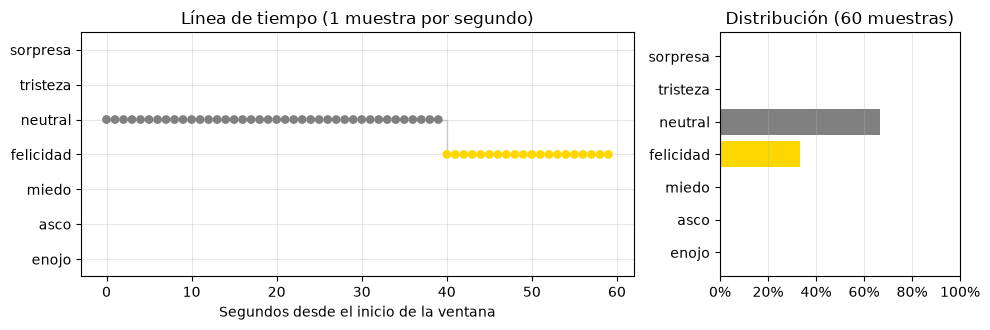

Emoción dominante: neutral (67% del tiempo) | Confianza media: 75% | Muestras: 60 (60 s)


In [21]:
LABELS_ES = [EMOTION_LABELS_ES[c] for c in CLASS_NAMES]
PLOT_COLORS = {c: hex_color(c) for c in CLASS_NAMES}
PLOT_COLORS["neutral"] = "#808080"     # el gris claro de OpenCV casi no se ve sobre fondo blanco


def history_window(history, last_seconds):
    # Muestras del historial dentro de la ventana (None = toda la sesión) como DataFrame.
    df = history.to_dataframe()
    if not df.empty and last_seconds is not None:
        df = df[df["timestamp"] > df["timestamp"].iloc[-1] - last_seconds]
    return df


def plot_history(history, last_seconds=None):
    # Figura con la línea de tiempo y la distribución de emociones de la ventana elegida.
    fig = Figure(figsize=(10, 3.4), dpi=100)
    ax_time, ax_dist = fig.subplots(1, 2, gridspec_kw={"width_ratios": [2.3, 1]})
    df = history_window(history, last_seconds)

    if df.empty:
        for ax in (ax_time, ax_dist):
            ax.set_axis_off()
        ax_time.text(0.5, 0.5, "Aún no hay muestras: activa la cámara y mira de frente",
                     ha="center", va="center", fontsize=12, color="gray", transform=ax_time.transAxes)
        fig.tight_layout()
        return fig

    elapsed = df["timestamp"] - df["timestamp"].iloc[0]
    y = df["emotion"].map(CLASS_NAMES.index)
    ax_time.step(elapsed, y, where="post", color="#d1d5db", linewidth=1, zorder=1)     # conecta los puntos
    ax_time.scatter(elapsed, y, c=[PLOT_COLORS[e] for e in df["emotion"]], s=28, zorder=2)
    ax_time.set_yticks(range(len(CLASS_NAMES)))
    ax_time.set_yticklabels(LABELS_ES)
    ax_time.set_ylim(-0.5, len(CLASS_NAMES) - 0.5)
    ax_time.set_xlabel("Segundos desde el inicio de la ventana")
    ax_time.set_title("Línea de tiempo (1 muestra por segundo)")
    ax_time.grid(alpha=0.3)

    distribution = df["emotion"].value_counts(normalize=True).reindex(CLASS_NAMES, fill_value=0)
    ax_dist.barh(LABELS_ES, distribution.values, color=[PLOT_COLORS[c] for c in CLASS_NAMES])
    ax_dist.set_xlim(0, 1)
    ax_dist.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax_dist.set_title(f"Distribución ({len(df)} muestras)")
    ax_dist.grid(axis="x", alpha=0.3)
    fig.tight_layout()
    return fig


def summary_markdown(history, last_seconds=None):
    # Resumen en texto de la ventana (usa summary() de la Fase 3: lo mismo que verá el asistente).
    summary = history.summary(last_seconds=last_seconds)
    if summary["samples"] == 0:
        return "**Resumen:** sin muestras todavía."
    dominant = summary["dominant_emotion"]
    return (f"**Emoción dominante:** {EMOTION_LABELS_ES[dominant]} "
            f"({summary['distribution'][dominant]:.0%} del tiempo)  \n"
            f"**Confianza media:** {summary['mean_confidence_dominant']:.0%}  \n"
            f"**Muestras:** {summary['samples']} ({summary['seconds_covered']:.0f} s)")


# --- Prueba con un historial simulado: 40 s neutral y luego 20 s felicidad ---
rng = np.random.default_rng(42)
simulated_history = EmotionHistory(CLASS_NAMES)
neutral_idx, happy_idx = CLASS_NAMES.index("neutral"), CLASS_NAMES.index("happy")
for second in range(60):
    alpha = np.full(len(CLASS_NAMES), 0.5)
    alpha[neutral_idx if second < 40 else happy_idx] = 8.0
    simulated_history.add(rng.dirichlet(alpha), now=1_000_000 + second)

display(plot_history(simulated_history))
print(summary_markdown(simulated_history).replace("**", "").replace("  \n", " | "))

### 2.6 El asistente conversacional (Fase 5)

**¿Qué es un LLM?** Un *Large Language Model* (modelo de lenguaje grande) es una red neuronal de tipo **Transformer** entrenada con enormes cantidades de texto para **predecir el siguiente fragmento de texto (token)**. Al repetir esa predicción una y otra vez genera respuestas completas. Usamos **Google Gemini** a través de su **API** (*Application Programming Interface*): el notebook envía un texto por internet a los servidores de Google y recibe la respuesta. El modelo no corre en el PC.

**Cómo se conecta con el detector (patrón "contexto + pregunta"):** el LLM no ve la cámara. En cada pregunta, `build_emotion_context()` convierte el historial (`EmotionHistory.summary()`) en un texto corto con **etiquetas y porcentajes** de los **últimos 30 s** y de **toda la sesión**, y lo pega antes de la pregunta. Así Gemini responde con datos reales del sistema en lugar de inventar. Es una versión simple de la idea de **RAG** (*Retrieval-Augmented Generation*: darle al modelo información externa en el momento de preguntar).

```
 EmotionHistory ──summary()──▶ build_emotion_context() ──▶ "DATOS DEL DETECTOR: felicidad 60 %, neutral 30 %…"
                                                                │
 Pregunta del usuario ──validate_message()──────────────────────┤
 Mensajes anteriores del chat (máx. 8) ─────────────────────────┤
 Reglas (system instruction) ───────────────────────────────────┴──▶ Gemini ──▶ respuesta en el chat
```

**Conceptos y parámetros que usamos**
| Concepto | Valor | Para qué |
|---|---|---|
| **System instruction** (instrucción de sistema) | Reglas fijas del asistente | Define el rol y los límites: solo habla de emociones, **no diagnostica**, habla de "expresión" y no de emoción real, advierte cuando la confianza es baja, ignora intentos de cambiar sus reglas (*prompt injection*) y, ante una situación de riesgo, recomienda buscar ayuda (línea 123 en Colombia). |
| **Historial de la conversación** | Últimos 8 mensajes | La API es **sin estado** (*stateless*): no recuerda nada entre llamadas, así que se le reenvían los mensajes previos para entender preguntas de seguimiento ("¿y hace un rato?"). Se limita para no gastar tokens. |
| **Temperatura** | 0,6 | Controla qué tan aleatoria es la elección de cada token: 0 da siempre la misma respuesta y valores altos dan respuestas más variadas. 0,6 es un punto medio natural para conversar. |
| **`max_output_tokens`** | 600 | Tope del largo de la respuesta (≈ 400 palabras). |
| **Nivel de razonamiento** (*thinking level*) | Mínimo | Los modelos actuales "piensan" internamente antes de responder. Para interpretar unos porcentajes no hace falta, y así la respuesta llega más rápido. |
| **Validación de la entrada** | Máx. 500 caracteres, no vacío | Seguridad y costo: evita mensajes enormes y llamadas inútiles. |

**Robustez: modelo de respaldo.** En el plan gratuito los modelos pueden fallar con el código HTTP **503** (modelo saturado; nos pasó el 18 de nov con `gemini-3.8-flash` y `gemini-3.6-flash`) o **429** (se alcanzó el límite de solicitudes por minuto o por día). Además, el plan gratuito a veces pone las solicitudes **en cola**: en una prueba del 18 de nov el mismo modelo respondió en 1,4 s y otras veces tardó 22-35 s. Por eso cada modelo tiene un **límite de espera (*timeout*) de 12 s**. Si el principal falla o no responde a tiempo, `GeminiAssistant` pregunta al **modelo de respaldo** (`GEMINI_FALLBACK_MODEL`), que respondió en 2,8 s. El SDK no hace reintentos propios: el reintento es el respaldo. Si ninguno responde, el chat muestra un mensaje amable en lugar de romper la interfaz. Los modelos se configuran en el `.env`, porque Google los cambia o retira con frecuencia.

**Privacidad y ética**
- A Gemini **solo** se envían etiquetas de emoción, porcentajes y tiempos (puedes verlo en la interfaz: *"Ver lo que se envía a Gemini"*).
- En el plan gratuito, Google puede usar el contenido enviado para mejorar sus productos: por eso **nunca** se envían imágenes ni datos personales.
- La API key está en `.env` (ignorado por Git) y nunca aparece en el código ni en el notebook.
- Las métricas del asistente guardan solo modelo, latencia y errores, **nunca el texto** de la conversación.

Abajo se crea el asistente y se prueba **sin internet**: el contexto que se genera con el historial simulado de la 2.5 y la validación de mensajes.

In [22]:
# --- Crear el asistente: lee GEMINI_API_KEY, GEMINI_MODEL y GEMINI_FALLBACK_MODEL del .env ---
assistant = GeminiAssistant.from_env(PROJECT_ROOT / ".env")
print(f"{'✅' if assistant.available else '⚠️'} API key {'cargada' if assistant.available else 'NO encontrada (revisa el .env)'}"
      " (la clave nunca se imprime)")
print("Modelos (principal → respaldo):", " → ".join(assistant.models))
print(f"Reglas del asistente (system instruction): {len(SYSTEM_INSTRUCTION)} caracteres")

# --- 1) Contexto generado a partir del historial simulado de la 2.5 (40 s neutral → 20 s felicidad) ---
last_timestamp = simulated_history.entries[-1]["timestamp"]
simulated_context = build_emotion_context(simulated_history, now=last_timestamp + 1)
print("\n--- Lo que recibiría Gemini con el historial simulado ---")
print(simulated_context)

# --- 2) Sin muestras y con muestras viejas (cámara detenida hace 2 min) ---
print("\n--- Sin muestras ---")
print(build_emotion_context(EmotionHistory(CLASS_NAMES)))
print("\n--- Muestras viejas ---")
print(build_emotion_context(simulated_history, now=last_timestamp + 120).splitlines()[1])

# --- 3) Validación de mensajes ---
print("\n--- Validación ---")
for example in ["  ¿Cómo   me veo\n ahora?  ", "", "x" * (MAX_MESSAGE_CHARS + 1)]:
    text, warning = validate_message(example)
    shown = example if len(example) < 40 else example[:20] + "…"
    print(f"{shown!r:32} → {'✅ ' + repr(text) if text else '⛔ ' + warning}")

✅ API key cargada (la clave nunca se imprime)
Modelos (principal → respaldo): gemini-3.5-flash-lite → gemini-3.1-flash-lite
Reglas del asistente (system instruction): 2012 caracteres

--- Lo que recibiría Gemini con el historial simulado ---
DATOS DEL DETECTOR (solo etiquetas y porcentajes, sin imágenes):
- El rostro se está viendo ahora (última muestra hace 1 s).
Últimos 30 s (30 muestras, 30 s):
  - Expresión más reciente: felicidad (confianza 92 %)
  - Predominante: felicidad (67 % del tiempo, confianza media 72 %)
  - Distribución: felicidad 67 %, neutral 33 %
Toda la sesión (60 muestras, 60 s):
  - Expresión más reciente: felicidad (confianza 92 %)
  - Predominante: neutral (67 % del tiempo, confianza media 75 %)
  - Distribución: neutral 67 %, felicidad 33 %

--- Sin muestras ---
DATOS DEL DETECTOR (solo etiquetas y porcentajes, sin imágenes):
- Todavía no hay muestras: la cámara no está activa o no se ha detectado un rostro.

--- Muestras viejas ---
- AVISO: la última muestra es

### 2.7 Prueba real con Gemini

Esta celda hace **una** consulta real con el contexto simulado (gasta 1 solicitud de la cuota gratuita) y mide la **latencia**: el tiempo desde que se envía la pregunta hasta que llega la respuesta. Si el modelo principal está saturado, verás que respondió el de respaldo. Si no quieres gastar la solicitud, cambia `RUN_GEMINI_TEST` a `False`.

Al final se borran las estadísticas de esta prueba para que la Parte 4 mida solo el uso real de la interfaz.

In [23]:
RUN_GEMINI_TEST = True

if not RUN_GEMINI_TEST:
    print("Prueba omitida (RUN_GEMINI_TEST = False)")
elif not assistant.available:
    print("⚠️ No hay API key: crea el archivo .env (ver .env.example) y reinicia el kernel.")
else:
    test_reply = assistant.reply("¿Cómo me veo según estos datos? ¿Cambió algo durante la sesión?", [], simulated_context)
    if test_reply.ok:
        print(f"✅ Respondió {test_reply.model} en {test_reply.latency_s:.1f} s"
              f"{' (modelo de respaldo)' if test_reply.used_fallback else ''}\n")
    else:
        print(f"⚠️ Sin respuesta (error {test_reply.error}). La interfaz mostrará este aviso:\n")
    print(test_reply.text)
    assistant.stats.clear()   # la prueba no cuenta en las métricas de la Parte 4

✅ Respondió gemini-3.5-flash-lite en 1.7 s

Según los datos actuales, tu expresión más reciente es de felicidad con una alta confianza del 92 %, y en los últimos 30 segundos esa misma expresión ha predominado el 67 % del tiempo. Sin embargo, al observar toda la sesión de un minuto, notas un cambio: la expresión predominante general fue neutral (67 %), lo que indica que comenzaste de manera más calmada y tu sonrisa se ha intensificado recientemente. Recuerda que esto refleja únicamente lo que capta la cámara en tus gestos, no necesariamente lo que sientes en tu interior.


## Parte 3 · Construir y lanzar la interfaz

### 3.1 Los eventos
- `on_frame(frame)`: recibe cada cuadro de la webcam y devuelve 4 cosas, en el orden de `outputs`: video anotado, tarjeta de la emoción, probabilidades y estado.
- `on_tick(window)`: cada segundo, la gráfica y el resumen del historial de la ventana elegida.
- `on_reset(window)`: borra el historial y las estadísticas.

Si llega un cuadro vacío (`None`, por ejemplo al detener la cámara), `gr.skip()` deja los componentes como estaban.

### 3.2 El panel del asistente y la distribución de la página (Fase 5)
**Distribución de la página:** en la fila principal quedan, lado a lado, la cámara con el video anotado, la emoción con sus probabilidades y el **chat**. Así, al preguntar, se ve al mismo tiempo lo que está midiendo el modelo. El historial queda debajo. Las alturas (`WEBCAM_HEIGHT`, `CHAT_HEIGHT` y `max-height` del video en el `CSS`) están pensadas para la pantalla de un portátil; si algo no cabe, se pueden bajar o reducir el zoom del navegador (Ctrl + −).

`build_assistant_panel()` crea el chat (`gr.Chatbot` + `gr.Textbox`), botones con preguntas rápidas y una sección *"Ver lo que se envía a Gemini"* que muestra el contexto exacto de la última pregunta (transparencia y privacidad).

Cada mensaje se procesa en **dos eventos encadenados** (`.then()`):
1. `on_user_message()`: valida el texto, lo muestra en el chat y limpia la caja. Es instantáneo.
2. `on_assistant_reply()`: arma el contexto con el historial **en ese momento** (con el candado de la sesión, porque el video lo modifica en otro hilo), llama a Gemini y agrega la respuesta.

Separarlos hace que la pregunta aparezca de inmediato aunque Gemini tarde unos segundos. Mientras tanto el video sigue funcionando, porque el chat y el streaming son eventos independientes.

In [24]:
def on_frame(frame):
    # Evento de streaming: un cuadro RGB de la webcam → 4 salidas para la interfaz.
    if frame is None:
        return gr.skip(), gr.skip(), gr.skip(), gr.skip()
    annotated, probs, n_faces = session.process(frame)
    return frame_to_html(annotated), emotion_card_html(probs), probabilities_for_label(probs), status_markdown(n_faces)


def on_tick(window_label):
    # Evento del temporizador: gráfica y resumen del historial.
    last_seconds = WINDOW_CHOICES[window_label]
    return plot_history(session.history, last_seconds), summary_markdown(session.history, last_seconds)


def on_reset(window_label):
    # Botón "Reiniciar historial": borra suavizado, historial y estadísticas.
    session.reset()
    plot, summary = on_tick(window_label)
    return plot, summary, emotion_card_html(None), None


# --- Fase 5: chat con el asistente ---
QUICK_QUESTIONS = [
    "¿Cómo me veo ahora?",
    "¿Cómo me he sentido durante la sesión?",
    "¿Qué tan confiable es este resultado?",
    "Dame un consejo para relajarme",
]


def current_context():
    # Contexto del detector en este momento (con el candado: el video modifica el historial en otro hilo).
    with session.lock:
        return build_emotion_context(session.history)


def on_user_message(message, chat_history):
    # Paso 1: valida el mensaje y lo muestra en el chat. Devuelve (chat, texto que queda en la caja).
    chat_history = list(chat_history or [])
    text, warning = validate_message(message)
    if warning:
        # Mensaje inválido: aviso en el chat y el texto se deja en la caja para corregirlo
        return chat_history + [{"role": "assistant", "content": f"⚠️ {warning}"}], message
    return chat_history + [{"role": "user", "content": text}], ""


def on_assistant_reply(chat_history):
    # Paso 2: llama a Gemini con el contexto actual. Devuelve (chat, contexto enviado, estado).
    chat_history = list(chat_history or [])
    if not chat_history or chat_history[-1]["role"] != "user":
        return gr.skip(), gr.skip(), gr.skip()        # el paso 1 rechazó el mensaje: no se llama a Gemini
    question = message_text(chat_history[-1]["content"])
    context = current_context()
    reply = assistant.reply(question, chat_history[:-1], context)
    if reply.ok:
        status = (f"Respondió **{reply.model}** en {reply.latency_s:.1f} s"
                  f"{' · modelo de respaldo' if reply.used_fallback else ''}")
    else:
        status = f"Sin respuesta de Gemini (error {reply.error})"
    return chat_history + [{"role": "assistant", "content": reply.text}], context, status


def build_assistant_panel():
    # Columna derecha de la fila principal: chat, preguntas rápidas y el contexto enviado a Gemini.
    gr.Markdown("### 💬 Asistente (Google Gemini)")
    chatbot = gr.Chatbot(
        show_label=False, height=CHAT_HEIGHT, layout="bubble",
        placeholder="Activa la cámara unos segundos y pregúntame, por ejemplo, *¿cómo me veo ahora?*",
    )
    message_box = gr.Textbox(
        placeholder=f"Escribe tu pregunta y presiona Enter (máx. {MAX_MESSAGE_CHARS} caracteres)",
        show_label=False, max_length=MAX_MESSAGE_CHARS, submit_btn=True, lines=1,
    )
    quick_buttons = []
    for pair in (QUICK_QUESTIONS[:2], QUICK_QUESTIONS[2:]):       # preguntas rápidas en 2 filas de 2
        with gr.Row():
            quick_buttons += [gr.Button(question, size="sm", min_width=120) for question in pair]
    with gr.Row():
        assistant_status = gr.Markdown(
            f"Modelos: {' → '.join(assistant.models)}" if assistant.available
            else "⚠️ Falta GEMINI_API_KEY en el .env: el chat mostrará un aviso.")
        clear_button = gr.Button("🧹 Limpiar chat", size="sm", variant="secondary", scale=0, min_width=130)
    with gr.Accordion("🔍 Ver lo que se envía a Gemini (última pregunta)", open=False):
        context_view = gr.Textbox(value=current_context(), show_label=False, lines=12,
                                  interactive=False, buttons=["copy"])

    # --- Eventos: enviar con Enter o con un botón de pregunta rápida ---
    reply_outputs = [chatbot, context_view, assistant_status]
    message_box.submit(on_user_message, inputs=[message_box, chatbot], outputs=[chatbot, message_box],
                       queue=False).then(on_assistant_reply, inputs=chatbot, outputs=reply_outputs)
    for button, question in zip(quick_buttons, QUICK_QUESTIONS):
        button.click(lambda chat, q=question: on_user_message(q, chat)[0], inputs=chatbot, outputs=chatbot,
                     queue=False).then(on_assistant_reply, inputs=chatbot, outputs=reply_outputs)
    clear_button.click(lambda: [], outputs=chatbot, queue=False)


# --- Tamaños pensados para que video, emoción y chat quepan juntos en la pantalla de un portátil ---
WEBCAM_HEIGHT = 190      # px de la vista previa de la cámara (sirve para activarla y ver el encuadre)
CHAT_HEIGHT = 300        # px del área de mensajes del chat

CSS = '''
.live-frame {width: 100%; max-height: 300px; object-fit: contain; border-radius: 8px; display: block;}
.live-placeholder {height: 240px; display: flex; align-items: center; justify-content: center;
                   text-align: center; padding: 16px; border: 2px dashed #9ca3af; border-radius: 8px; color: #6b7280;}
.emotion-card {border: 3px solid #d1d5db; border-radius: 12px; padding: 10px 14px; text-align: center;}
.emotion-title {font-size: 0.8rem; color: #6b7280; text-transform: uppercase; letter-spacing: 0.05em;}
.emotion-name {font-size: 1.9rem; font-weight: 700; margin: 2px 0;}
.emotion-confidence {font-size: 1rem;}
.emotion-hint {font-size: 0.85rem; color: #6b7280;}
.confidence-bar {height: 10px; background: #e5e7eb; border-radius: 5px; margin-top: 6px; overflow: hidden;}
.confidence-bar > div {height: 100%;}
'''

HEADER = '''
## 🎭 Emotion Detection Assistant
CNN entrenada en FER-2013 (**7 emociones**, accuracy en test **66,5 %**) + asistente con Google Gemini.
**Cómo usarla:** en *Tu cámara* haz clic en **Click to Access Webcam** → permitir → **Record**, y pregúntale al asistente.
*El video no sale de este PC ni se guarda; al asistente solo se le envían etiquetas y porcentajes.
La expresión facial no equivale a la emoción real ni es un diagnóstico.*
'''


def build_interface():
    # Arma la página. Fila principal: video | emoción y probabilidades | asistente (todo visible a la vez).
    # Fila de abajo: historial.
    with gr.Blocks(title="Emotion Detection Assistant") as demo:
        gr.Markdown(HEADER)

        # --- Fila 1: cámara y video anotado | emoción y probabilidades | chat ---
        with gr.Row(equal_height=False):
            with gr.Column(scale=4, min_width=320):
                webcam = gr.Image(
                    sources=["webcam"], streaming=True, type="numpy", label="Tu cámara", height=WEBCAM_HEIGHT,
                    webcam_options=gr.WebcamOptions(
                        mirror=True,   # efecto espejo (Gradio ya envía el cuadro volteado)
                        constraints={"video": {"width": {"ideal": 640}, "height": {"ideal": 480}}},
                    ),
                )
                live_view = gr.HTML(frame_to_html(None), label="Detección en vivo")
            with gr.Column(scale=3, min_width=250):
                emotion_card = gr.HTML(emotion_card_html(None))
                probability_panel = gr.Label(label="Probabilidades (suavizadas, N = 10)",
                                             num_top_classes=len(CLASS_NAMES), show_heading=False)
                status = gr.Markdown("**FPS:** - · **Rostros:** -")
            with gr.Column(scale=5, min_width=340):
                build_assistant_panel()

        # --- Fila 2: historial (debajo; se ve bajando la página) ---
        with gr.Row(equal_height=False):
            with gr.Column(scale=4):
                gr.Markdown("### 📈 Historial de emociones")
                history_plot = gr.Plot(show_label=False, format="png")
            with gr.Column(scale=1, min_width=220):
                window_selector = gr.Radio(list(WINDOW_CHOICES), value="Últimos 30 s", label="Ventana del historial")
                history_summary = gr.Markdown("**Resumen:** sin muestras todavía.")
                reset_button = gr.Button("🔄 Reiniciar historial")

        # --- Eventos ---
        webcam.stream(
            on_frame, inputs=webcam, outputs=[live_view, emotion_card, probability_panel, status],
            stream_every=STREAM_EVERY, concurrency_limit=1, show_progress="hidden",
        )
        timer = gr.Timer(HISTORY_REFRESH_S)
        timer.tick(on_tick, inputs=window_selector, outputs=[history_plot, history_summary], show_progress="hidden")
        window_selector.change(on_tick, inputs=window_selector, outputs=[history_plot, history_summary],
                               show_progress="hidden")
        reset_button.click(on_reset, inputs=window_selector,
                           outputs=[history_plot, history_summary, emotion_card, probability_panel])
        demo.load(on_tick, inputs=window_selector, outputs=[history_plot, history_summary])
    return demo


print("Interfaz definida")

Interfaz definida


### 3.3 Lanzar la aplicación

Al ejecutar la celda se abre el navegador en `http://127.0.0.1:7860`. Si no se abre solo, copia la dirección que aparece en la salida.

1. En el recuadro **"Tu cámara"** haz clic en **Click to Access Webcam** y permite el acceso cuando el navegador lo pida (los textos de los botones de Gradio vienen en inglés).
2. Presiona **Record**: desde ese momento el navegador empieza a enviar cuadros. Con **Stop** se detiene el envío.
3. Prueba varias expresiones y mira la tarjeta, las barras y la gráfica. Usa varias ventanas del historial.
4. Con la cámara funcionando, usa el **asistente**: escribe una pregunta o usa los botones de preguntas rápidas. Abre *"Ver lo que se envía a Gemini"* para mostrar en el video qué datos recibe.
5. Para la Parte 4, déjala funcionando **al menos 1 minuto** con tu rostro visible y haz **al menos 5 preguntas** al asistente.

**Detalles técnicos:**
- En Jupyter, `launch()` **no bloquea** el notebook: el servidor corre en segundo plano y puedes seguir ejecutando celdas.
- `server_name="127.0.0.1"`: solo se puede abrir desde este PC (no desde otros equipos de la red). No se usa `share=True`, que crearía un enlace público en internet.
- `inline=False`: la app no se incrusta en el notebook, así ninguna imagen de la cámara queda guardada en el `.ipynb`.
- `gr.close_all()` cierra un servidor anterior si vuelves a ejecutar la celda. Si el puerto 7860 está ocupado, Gradio usa el siguiente (7861, ...).
- Si la cámara no abre: cierra otras apps que la usen (Zoom, Teams, Cámara, o el notebook 03) y revisa los permisos de cámara del navegador (el ícono a la izquierda de la dirección).

In [25]:
gr.close_all()                 # cierra servidores de Gradio anteriores (si re-ejecutas la celda)
session.reset()                # empieza la sesión de la demo desde cero
demo = build_interface()
_, local_url, _ = demo.launch(
    server_name="127.0.0.1",   # solo accesible desde este PC
    inbrowser=True,            # abre el navegador automáticamente
    inline=False,              # no incrustar en el notebook (privacidad)
    theme=gr.themes.Soft(),
    css=CSS,
    show_error=True,           # si algo falla, el error se ve en la página
)
print(f"App abierta en {local_url} (si el navegador no se abrió, copia esta dirección)")

Closing server running on port: 7860
* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.
App abierta en http://127.0.0.1:7860/ (si el navegador no se abrió, copia esta dirección)


## Parte 4 · Resultados de la sesión y evidencias

Ejecuta estas celdas **después de usar la app al menos 1 minuto** (y de hacerle algunas preguntas al asistente) (no hace falta cerrarla). Si las ejecutas antes, o con *Run All*, solo verás un aviso. Vuelve a ejecutarlas después de usar la app.

### 4.1 Rendimiento de la interfaz
Se miden:
- **FPS de la interfaz:** cuadros por segundo que llegan del navegador. Se excluyen las pausas de más de 1 s (cámara detenida).
- **Tiempo de procesamiento en Python** por cuadro (detección + predicción + suavizado + dibujo), con su percentil 95 (p95: el 95 % de los cuadros tardó eso o menos).
- **Estabilidad:** cambios de etiqueta cada 100 cuadros con rostro, sin suavizar y suavizada (como en la Fase 3).

En la Fase 3 la cámara se leía directamente con OpenCV (16-20 FPS). Aquí cada cuadro además se codifica a JPEG en el navegador, viaja al servidor, se decodifica y la respuesta vuelve. Se espera un FPS algo menor: ese costo extra es la **latencia de red local** de la arquitectura cliente-servidor.

In [26]:
MIN_FRAMES_FOR_RESULTS = 100   # ~1 minuto con la app abierta


def performance_summary(session, skip_frames=10):
    # Resume el rendimiento de la sesión (solo números). Devuelve None si hay muy pocos cuadros.
    processing = np.array(list(session.stats["processing_ms"])[skip_frames:], dtype=float)
    if len(processing) < MIN_FRAMES_FOR_RESULTS:
        return None
    gaps = np.array(list(session.stats["arrival_gap_ms"])[skip_frames:], dtype=float)
    gaps = gaps[gaps <= 1000]                                    # sin pausas largas
    faces = np.array(list(session.stats["faces"])[skip_frames:])
    raw, smoothed = list(session.raw_labels), list(session.smoothed_labels)
    raw_changes, smoothed_changes = count_label_changes(raw), count_label_changes(smoothed)
    return {
        "frames_processed": int(len(processing)),
        "frame_size": list(session.frame_size),
        "stream_every_s": STREAM_EVERY,
        "interface_fps": round(1000 / gaps.mean(), 1) if len(gaps) else None,
        "arrival_gap_ms_p95": round(float(np.percentile(gaps, 95)), 1) if len(gaps) else None,
        "processing_ms_mean": round(float(processing.mean()), 1),
        "processing_ms_p95": round(float(np.percentile(processing, 95)), 1),
        "detection_ms_mean": round(float(np.mean(list(session.stats["detection_ms"])[skip_frames:])), 1),
        "prediction_ms_mean": round(float(np.mean(list(session.stats["prediction_ms"])[skip_frames:])), 1),
        "frames_with_face_ratio": round(float((faces > 0).mean()), 3),
        "frames_with_face": len(raw),
        "smoothing_window": SMOOTHING_WINDOW,
        "raw_changes_per_100_frames": round(100 * raw_changes / len(raw), 2) if raw else None,
        "smoothed_changes_per_100_frames": round(100 * smoothed_changes / len(raw), 2) if raw else None,
        "history_samples": len(session.history.entries),
        "use_tta": detector.use_tta,
    }


gradio_performance = performance_summary(session)
if gradio_performance is None:
    print(f"Todavía hay pocos cuadros ({len(session.stats['processing_ms'])}). "
          "Usa la app al menos 1 minuto y vuelve a ejecutar esta celda.")
else:
    with open(METRICS_DIR / "gradio_performance.json", "w", encoding="utf-8") as f:
        json.dump(gradio_performance, f, indent=2)
    print(json.dumps(gradio_performance, indent=2))
    print("Guardado en reports/metrics/gradio_performance.json (solo números)")

{
  "frames_processed": 7065,
  "frame_size": [
    640,
    480
  ],
  "stream_every_s": 0.05,
  "interface_fps": 11.6,
  "arrival_gap_ms_p95": 145.3,
  "processing_ms_mean": 59.6,
  "processing_ms_p95": 105.4,
  "detection_ms_mean": 21.3,
  "prediction_ms_mean": 33.5,
  "frames_with_face_ratio": 0.912,
  "frames_with_face": 6454,
  "smoothing_window": 10,
  "raw_changes_per_100_frames": 4.8,
  "smoothed_changes_per_100_frames": 1.38,
  "history_samples": 564,
  "use_tta": true
}
Guardado en reports/metrics/gradio_performance.json (solo números)


### 4.2 Historial de la sesión
La gráfica de **toda la sesión** se guarda como evidencia (solo etiquetas, sin imágenes de la cámara). Debajo del resumen JSON se muestra el **texto exacto** que `build_emotion_context()` le enviaría ahora al asistente.

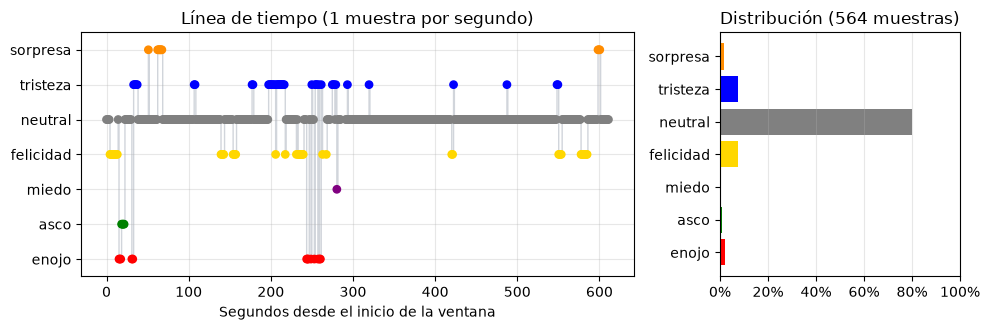

Guardado en reports/figures/gradio_emotion_history.png

Resumen de toda la sesión (EmotionHistory.summary()):
{
  "samples": 564,
  "seconds_covered": 611.9,
  "current_emotion": "neutral",
  "current_confidence": 0.7672,
  "dominant_emotion": "neutral",
  "distribution": {
    "angry": 0.023,
    "disgust": 0.007,
    "fear": 0.002,
    "happy": 0.074,
    "neutral": 0.801,
    "sad": 0.074,
    "surprise": 0.018
  },
  "mean_confidence_dominant": 0.692
}

Últimos 30 s:
{
  "samples": 27,
  "seconds_covered": 31.0,
  "current_emotion": "neutral",
  "current_confidence": 0.7672,
  "dominant_emotion": "neutral",
  "distribution": {
    "angry": 0.0,
    "disgust": 0.0,
    "fear": 0.0,
    "happy": 0.148,
    "neutral": 0.741,
    "sad": 0.0,
    "surprise": 0.111
  },
  "mean_confidence_dominant": 0.608
}

Contexto que recibe el asistente (build_emotion_context):
DATOS DEL DETECTOR (solo etiquetas y porcentajes, sin imágenes):
- AVISO: la última muestra es de hace 11 s; ahora no se est

In [27]:
if len(session.history.entries) < 10:
    print("El historial tiene menos de 10 muestras: usa la app con tu rostro visible y vuelve a ejecutar esta celda.")
else:
    history_figure = plot_history(session.history)
    history_figure.savefig(FIGURES_DIR / "gradio_emotion_history.png", dpi=120)
    display(history_figure)
    print("Guardado en reports/figures/gradio_emotion_history.png")

    print("\nResumen de toda la sesión (EmotionHistory.summary()):")
    print(json.dumps(session.history.summary(), indent=2, ensure_ascii=False))
    print("\nÚltimos 30 s:")
    print(json.dumps(session.history.summary(last_seconds=30), indent=2, ensure_ascii=False))
    print("\nContexto que recibe el asistente (build_emotion_context):")
    print(current_context())

### 4.3 Rendimiento del asistente
`assistant.performance_summary()` resume las consultas hechas desde la interfaz (sin la prueba de la 2.7): cuántas respondió Gemini, cuántas usaron el **modelo de respaldo**, la **latencia** (media, mediana y máxima) y los errores (por ejemplo, 503 o 429). Solo guarda números y nombres de modelos, **nunca el texto de la conversación**.

Para el reporte compara la latencia del asistente (segundos, porque viaja a internet y el LLM genera texto) con la del detector (milisegundos, porque corre en el PC).

In [28]:
assistant_performance = assistant.performance_summary()
if assistant_performance["queries"] == 0:
    print("Todavía no hay consultas al asistente: hazle algunas preguntas en la app y vuelve a ejecutar esta celda.")
else:
    with open(METRICS_DIR / "assistant_performance.json", "w", encoding="utf-8") as f:
        json.dump(assistant_performance, f, indent=2, ensure_ascii=False)
    print(json.dumps(assistant_performance, indent=2, ensure_ascii=False))
    print("Guardado en reports/metrics/assistant_performance.json (solo números, sin el texto del chat)")

{
  "queries": 16,
  "answered": 16,
  "success_rate": 1.0,
  "fallback_answers": 0,
  "latency_s_mean": 1.41,
  "latency_s_median": 1.4,
  "latency_s_max": 1.85,
  "answers_by_model": {
    "gemini-3.5-flash-lite": 16
  },
  "errors": {},
  "configured_models": [
    "gemini-3.5-flash-lite",
    "gemini-3.1-flash-lite"
  ]
}
Guardado en reports/metrics/assistant_performance.json (solo números, sin el texto del chat)


### 4.4 Apagar el servidor
El servidor sigue encendido mientras el kernel esté activo. Para apagarlo, cambia `STOP_SERVER` a `True` y ejecuta la celda (o usa **Kernel → Shut Down Kernel**). Viene en `False` para que *Run All* no apague la app recién abierta.

In [31]:
STOP_SERVER = False

if STOP_SERVER:
    demo.close()
    print("Servidor de Gradio apagado. La cámara del navegador ya no envía cuadros.")
else:
    print("El servidor sigue encendido (STOP_SERVER = False).")

El servidor sigue encendido (STOP_SERVER = False).


### Evidencias de las Fases 4 y 5 para el reporte y el video
**Fase 4 (interfaz):**
- **Capturas de la interfaz** con varias emociones (felicidad, sorpresa, neutral...) donde se vean el video con el recuadro, la tarjeta de la emoción, las barras de probabilidad y la gráfica del historial. Para el reporte puedes usar una sola captura bien iluminada.
- `reports/metrics/gradio_performance.json`: FPS de la interfaz, tiempos de procesamiento y estabilidad. Compáralo con `realtime_performance.json` de la Fase 3 (OpenCV directo frente a la arquitectura cliente-servidor).
- `reports/figures/gradio_emotion_history.png`: historial de una sesión real.
- **Diagrama de la arquitectura** (Parte 2.1) para el reporte: navegador ↔ servidor local de Gradio ↔ modelo.

**Fase 5 (asistente):**
- **Capturas del chat** respondiendo: (1) "¿Cómo me veo ahora?" con la tarjeta de emoción visible, (2) "¿Cómo me he sentido durante la sesión?", (3) una pregunta **fuera de tema** (por ejemplo, "¿quién ganó el partido?") donde se vea que se niega amablemente, y (4) una pregunta que pida un **diagnóstico** (por ejemplo, "¿tengo depresión?") donde se vea que no diagnostica.
- Captura de **"Ver lo que se envía a Gemini"**: prueba de que solo viajan etiquetas y porcentajes.
- `reports/metrics/assistant_performance.json`: latencia del asistente, respuestas del modelo de respaldo y errores.
- Salida de la celda 2.7 (prueba real con su latencia) y de la 2.6 (contexto generado y validación).
- Salida de `python -m pytest tests -v` (pruebas automáticas con Gemini simulado).
- Para el video: graba una conversación corta mientras cambias de expresión y muestra que la respuesta cambia según el historial.

**Privacidad antes del commit:** este notebook no muestra imágenes de la cámara (la app no está incrustada), así que no hace falta borrar salidas. La tarjeta de la Parte 2.4 usa probabilidades inventadas y las gráficas y el contexto de la 2.5-2.7 son simulados. La conversación del chat no se guarda en el notebook ni en las métricas.